# Euro 2020 — Match EDA (Events + 360)
This notebook explores a single match with:
- Event log (passes, shots, carries, duels, etc.)
- 360 freeze-frames (player locations around events)
- Links to lineups and matches metadata

Popular metrics included:
- xG & shot map
- Progressive passes
- Field tilt (final-third share)
- PPDA (pressing intensity proxy)
- Passing network
- Nearest defender distance on shots
- Freeze-frame visualizations

Notes:
- StatsBomb pitch coordinates are 120 (length) x 80 (width). (We rely on that convention.)
- 360 'freeze frames' give teammates/opponents positions + visible area for an event.



## 0) Imports & Paths

In [1]:
# %%
import json
import math
from typing import Any, Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle, ConnectionPatch, Polygon

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 6)

# ---- file paths: update the match_id file names accordingly ----
MATCHES_CSV   = "matches_df.csv"
LINEUPS_CSV   = "lineups_df.csv"
EVENTS_CSV    = "events_by_match/events_3788741.csv"         # change to your chosen match file
FRAMES360_CSV = "frames_360_by_match/frames_360_3788741.csv"     # same match_id


## 1) Load & Light Inspect

In [2]:
# %%
matches = pd.read_csv(MATCHES_CSV)
lineups = pd.read_csv(LINEUPS_CSV)
events  = pd.read_csv(EVENTS_CSV)
frames  = pd.read_csv(FRAMES360_CSV)

print("matches:", matches.shape, "| lineups:", lineups.shape, "| events:", events.shape, "| frames:", frames.shape)
print("\nEvents head columns:", list(events.columns[:20]))
print("Frames head columns:", list(frames.columns))


matches: (51, 22) | lineups: (2345, 10) | events: (3803, 115) | frames: (45737, 7)

Events head columns: ['fifty_fifty', 'bad_behaviour_card', 'ball_receipt_outcome', 'ball_recovery_offensive', 'ball_recovery_recovery_failure', 'block_deflection', 'block_offensive', 'block_save_block', 'carry_end_location', 'clearance_aerial_won', 'clearance_body_part', 'clearance_head', 'clearance_left_foot', 'clearance_other', 'clearance_right_foot', 'counterpress', 'dribble_no_touch', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun']
Frames head columns: ['id', 'match_id', 'visible_area', 'teammate', 'actor', 'keeper', 'location']


## 2) Keys & Joins

In [3]:
# %%
assert "match_id" in events.columns and "id" in events.columns, "events missing match_id or id"
assert "match_id" in frames.columns and "id" in frames.columns, "frames missing match_id or id"

# choose the match_id present in the event file (assume one match)
match_id = int(events["match_id"].mode().iloc[0])
mrow = matches.loc[matches["match_id"] == match_id]
print(f"Match row found? {not mrow.empty} | match_id={match_id}")

# helpful: infer side (home/away) from team name
def infer_side(team_name: str, home: str, away: str) -> Optional[str]:
    if pd.isna(team_name):
        return None
    if team_name == home:
        return "home"
    if team_name == away:
        return "away"
    return None

if not mrow.empty and {"home_team","away_team"}.issubset(mrow.columns):
    home, away = mrow.iloc[0]["home_team"], mrow.iloc[0]["away_team"]
    events["side"] = events["team"].apply(lambda t: infer_side(t, home, away))
else:
    events["side"] = None

# confirm coverage: fraction of events that have frames
has_frames = events["id"].isin(frames["id"]).mean()
print(f"Share of events with 360 freeze-frames: {has_frames:0.2%}")


Match row found? True | match_id=3788741
Share of events with 360 freeze-frames: 88.61%


## 3) Helpers — Parsing & Pitch

In [7]:
# %%
def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:
        return json.loads(s)
    except Exception:
        # some CSVs store lists as like "[52.3, 33.2]"
        # or with single quotes — try a fallback
        try:
            return json.loads(s.replace("'", '"'))
        except Exception:
            return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])
    return None

def draw_pitch(ax=None, linecolor="black", lw=1):
    if ax is None:
        ax = plt.gca()
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 80)
    ax.set_aspect("equal")
    ax.axis("off")
    # outline & halves
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)
    # boxes
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))      # left box
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))     # right box
    # six-yard
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    # penalty spots & arcs
    ax.plot(12, 40, 'o', color=linecolor, ms=2)
    ax.plot(108, 40, 'o', color=linecolor, ms=2)
    ax.add_patch(Arc((12, 40), 20, 20, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 20, 20, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))
    # center circle
    ax.add_patch(Arc((60, 40), 20, 20, angle=0, theta1=0, theta2=360, ec=linecolor, lw=lw))
    return ax


## 4) Basic Match Context

In [8]:
# %%
if not mrow.empty:
    cols = ["match_date","kick_off","competition","season","home_team","away_team","home_score","away_score"]
    print(mrow[cols].to_string(index=False))
else:
    print("Match metadata not found in matches_df.")


match_date     kick_off        competition  season home_team away_team  home_score  away_score
2021-06-11 21:00:00.000 Europe - UEFA Euro    2020    Turkey     Italy           0           3


## 5) Shots & xG Overview (popular)

Shot / xG summary by team:
         shots  goals     xg  avg_xg
team                               
Italy      24      2  1.591   0.066
Turkey      3      0  0.151   0.050


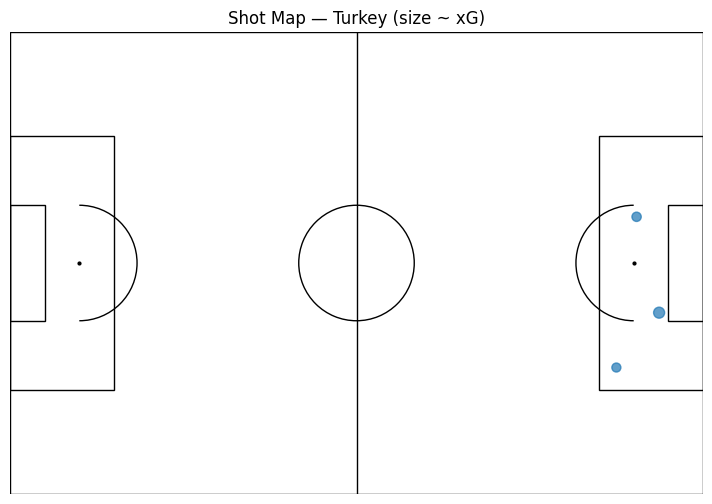

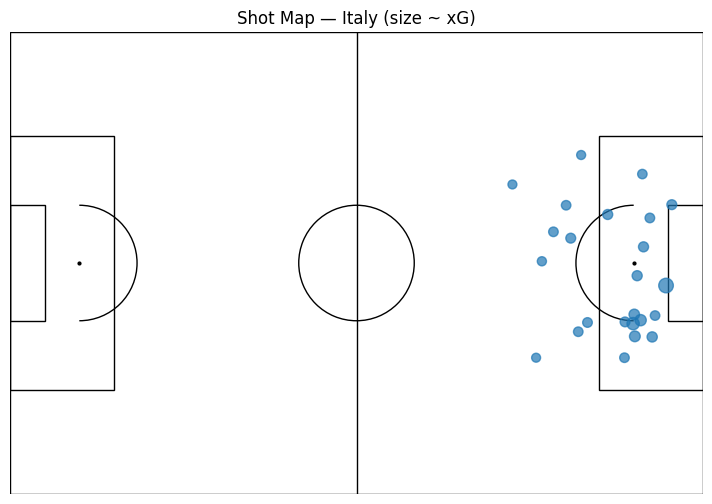

In [10]:
# %%
shots = events[events["type"] == "Shot"].copy()
shots["xy"] = shots["location"].apply(try_json).apply(parse_point)
shots["end_xy"] = shots["shot_end_location"].apply(try_json).apply(parse_point) if "shot_end_location" in shots.columns else None

shots["x"] = shots["xy"].apply(lambda p: p[0] if p else np.nan)
shots["y"] = shots["xy"].apply(lambda p: p[1] if p else np.nan)
if "shot_statsbomb_xg" in shots.columns:
    shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
else:
    shots["xg"] = np.nan

summary = shots.groupby("team").agg(
    shots=("id","count"),
    goals=("shot_outcome", lambda s: (s=="Goal").sum() if s is not None else np.nan),
    xg=("xg","sum"),
    avg_xg=("xg","mean")
).sort_values("xg", ascending=False)
print("Shot / xG summary by team:\n", summary.fillna(0).round(3))

# --- Plot: shot map colored by xG (one example: home team) ---
home_team = mrow.iloc[0]["home_team"] if not mrow.empty else shots["team"].iloc[0]
subset = shots[shots["team"] == home_team]

fig, ax = plt.subplots()
draw_pitch(ax)
sc = ax.scatter(subset["x"], subset["y"], s=40 + 200*subset["xg"].fillna(0), alpha=0.7)
ax.set_title(f"Shot Map — {home_team} (size ~ xG)")
plt.show()

# --- Plot: shot map colored by xG (one example: home team) ---
away_team = mrow.iloc[0]["away_team"] if not mrow.empty else shots["team"].iloc[0]
subset = shots[shots["team"] == away_team]

fig, ax = plt.subplots()
draw_pitch(ax)
sc = ax.scatter(subset["x"], subset["y"], s=40 + 200*subset["xg"].fillna(0), alpha=0.7)
ax.set_title(f"Shot Map — {away_team} (size ~ xG)")
plt.show()

## 6) Progressive Passes (popular)
A pass that moves the ball **closer to goal** by a meaningful amount.
We'll use a pragmatic rule of thumb:
- Ends at least 10m closer to the center of the opposition goal (x increases toward 120).
- Or ends inside the box if it started outside.
(There are several definitions in the wild; adjust thresholds to taste.)


In [12]:
# %%
passes = events[events["type"] == "Pass"].copy()
passes["start"] = passes["location"].apply(try_json).apply(parse_point)
passes["end"] = passes["pass_end_location"].apply(try_json).apply(parse_point)

def prog_pass(row) -> Optional[bool]:
    s, e = row["start"], row["end"]
    if not s or not e:
        return None
    # distance toward opponent goal center (x=120, y=40)
    start_to_goal = math.hypot(120 - s[0], 40 - s[1])
    end_to_goal   = math.hypot(120 - e[0], 40 - e[1])
    closer = (start_to_goal - end_to_goal) >= 10.0  # ~10m threshold
    # box override
    in_box = (102 <= e[0] <= 120) and (18 <= e[1] <= 62)
    return bool(closer or in_box)

passes["is_progressive"] = passes.apply(prog_pass, axis=1)

prog_summary = passes.groupby("team")["is_progressive"].mean().rename("progressive_rate").sort_values(ascending=False)
print("Share of progressive passes by team:\n", prog_summary.round(3))


Share of progressive passes by team:
 team
Turkey    0.318
Italy     0.283
Name: progressive_rate, dtype: float64


## 7) Field Tilt (popular)
Field tilt ≈ share of **final-third** actions for each team.
Approximation: use events with `location.x >= 80` (final third on 120-length pitch),
count **completed passes + ball touches** there, then compute share.
Rationale: It's a territory proxy (final-third possession share).


In [13]:
# %%
def in_final_third(pt):
    if not pt:
        return False
    return pt[0] >= 80  # final third

# consider events that represent controlled touches in final third
touchlike = events[events["type"].isin(["Pass", "Carry", "Ball Receipt*", "Dribble", "Shot"])].copy()
touchlike["pt"] = touchlike["location"].apply(try_json).apply(parse_point)
ft_touches = touchlike["pt"].apply(in_final_third)

ft_by_team = touchlike.loc[ft_touches].groupby("team")["id"].count()
field_tilt = (ft_by_team / ft_by_team.sum()).sort_values(ascending=False)
print("Field Tilt (final-third touch share):\n", field_tilt.round(3))


Field Tilt (final-third touch share):
 team
Italy     0.836
Turkey    0.164
Name: id, dtype: float64


## 8) PPDA (popular pressing proxy)
PPDA ≈ Opponent **Passes** divided by Defensive Actions (tackles/interceptions/challenges/fouls)
in attacking 60% of the field (higher x). Lower PPDA → more intense press.
We'll approximate with events in `x >= 48` (60% of 120).


In [14]:
# %%
def in_pressing_zone(pt):
    return bool(pt and pt[0] >= 48)

events["pt"] = events["location"].apply(try_json).apply(parse_point)

# passes by Team A in A's buildup zone are "opponent passes" for Team B's PPDA
passes_mask = (events["type"] == "Pass")
def_actions_mask = events["type"].isin(["Pressure", "Foul Committed", "Duel", "Interception", "Tackle", "Block"])

team_names = events["team"].dropna().unique()
ppda = {}
for team in team_names:
    opp = team_names[team_names != team]
    opp_passes = events[passes_mask & events["pt"].apply(in_pressing_zone) & events["team"].isin(opp)]["id"].count()
    def_actions = events[def_actions_mask & events["pt"].apply(in_pressing_zone) & (events["team"] == team)]["id"].count()
    ppda[team] = (opp_passes / def_actions) if def_actions > 0 else np.nan

ppda = pd.Series(ppda).sort_values()
print("PPDA (lower = more intense press):\n", ppda.round(2))


PPDA (lower = more intense press):
 Italy     0.97
Turkey    3.60
dtype: float64


## 9) Passing Network (popular)
- Nodes = players (size by touches), edges = completed pass counts between teammates.
- We'll focus on one team to keep the plot readable.


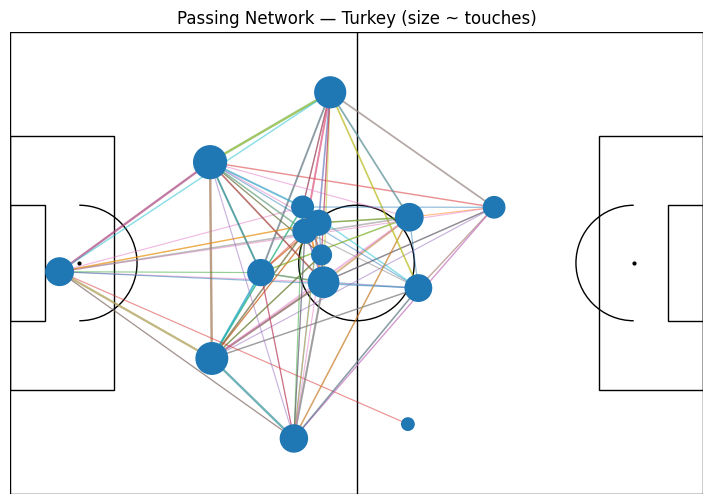

In [15]:
# %%
team_focus = mrow.iloc[0]["home_team"] if not mrow.empty else events["team"].dropna().unique()[0]

team_pass = passes[(passes["team"] == team_focus) & (passes["pass_outcome"].isna())].copy()
pair_counts = team_pass.groupby(["player_id","pass_recipient_id"]).size().rename("count").reset_index()

touch_counts = events[(events["team"] == team_focus) & events["player_id"].notna()].groupby("player_id").size().rename("touches").reset_index()

# naive player positions for plotting network: average starting location of their passes/receipts
start_pos = team_pass.groupby("player_id")["start"].apply(lambda s: np.nanmean(np.vstack([p for p in s if p]), axis=0) if any(s) else np.array([60,40]))
recv_pos  = team_pass.groupby("pass_recipient_id")["end"].apply(lambda s: np.nanmean(np.vstack([p for p in s if p]), axis=0) if any(s) else np.array([60,40]))
avg_pos = pd.DataFrame({
    "player_id": start_pos.index,
    "x": [p[0] if isinstance(p, np.ndarray) else 60 for p in start_pos.values],
    "y": [p[1] if isinstance(p, np.ndarray) else 40 for p in start_pos.values]
}).merge(
    pd.DataFrame({
        "player_id": recv_pos.index,
        "x2": [p[0] if isinstance(p, np.ndarray) else 60 for p in recv_pos.values],
        "y2": [p[1] if isinstance(p, np.ndarray) else 40 for p in recv_pos.values]
    }),
    how="outer", on="player_id"
)
avg_pos["x"] = avg_pos[["x","x2"]].mean(axis=1)
avg_pos["y"] = avg_pos[["y","y2"]].mean(axis=1)
avg_pos = avg_pos.drop(columns=["x2","y2"]).merge(touch_counts, on="player_id", how="left")

# plot
fig, ax = plt.subplots()
draw_pitch(ax)
# edges
for r in pair_counts.itertuples(index=False):
    a = avg_pos.loc[avg_pos["player_id"]==r.player_id, ["x","y"]].values
    b = avg_pos.loc[avg_pos["player_id"]==r.pass_recipient_id, ["x","y"]].values
    if len(a)==1 and len(b)==1:
        ax.plot([a[0,0], b[0,0]], [a[0,1], b[0,1]], linewidth=0.5 + 0.5*np.log1p(r.count), alpha=0.5)

# nodes
ax.scatter(avg_pos["x"], avg_pos["y"], s=50 + 3*avg_pos["touches"].fillna(0), zorder=3)
ax.set_title(f"Passing Network — {team_focus} (size ~ touches)")
plt.show()


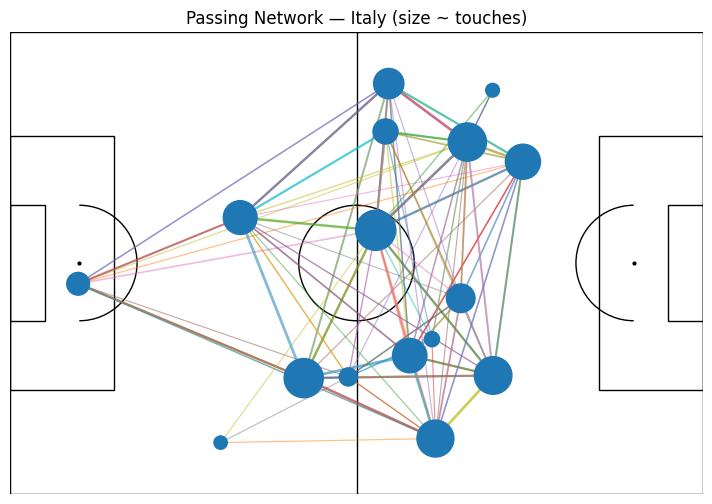

In [16]:
# %%
team_focus = mrow.iloc[0]["away_team"] if not mrow.empty else events["team"].dropna().unique()[0]

team_pass = passes[(passes["team"] == team_focus) & (passes["pass_outcome"].isna())].copy()
pair_counts = team_pass.groupby(["player_id","pass_recipient_id"]).size().rename("count").reset_index()

touch_counts = events[(events["team"] == team_focus) & events["player_id"].notna()].groupby("player_id").size().rename("touches").reset_index()

# naive player positions for plotting network: average starting location of their passes/receipts
start_pos = team_pass.groupby("player_id")["start"].apply(lambda s: np.nanmean(np.vstack([p for p in s if p]), axis=0) if any(s) else np.array([60,40]))
recv_pos  = team_pass.groupby("pass_recipient_id")["end"].apply(lambda s: np.nanmean(np.vstack([p for p in s if p]), axis=0) if any(s) else np.array([60,40]))
avg_pos = pd.DataFrame({
    "player_id": start_pos.index,
    "x": [p[0] if isinstance(p, np.ndarray) else 60 for p in start_pos.values],
    "y": [p[1] if isinstance(p, np.ndarray) else 40 for p in start_pos.values]
}).merge(
    pd.DataFrame({
        "player_id": recv_pos.index,
        "x2": [p[0] if isinstance(p, np.ndarray) else 60 for p in recv_pos.values],
        "y2": [p[1] if isinstance(p, np.ndarray) else 40 for p in recv_pos.values]
    }),
    how="outer", on="player_id"
)
avg_pos["x"] = avg_pos[["x","x2"]].mean(axis=1)
avg_pos["y"] = avg_pos[["y","y2"]].mean(axis=1)
avg_pos = avg_pos.drop(columns=["x2","y2"]).merge(touch_counts, on="player_id", how="left")

# plot
fig, ax = plt.subplots()
draw_pitch(ax)
# edges
for r in pair_counts.itertuples(index=False):
    a = avg_pos.loc[avg_pos["player_id"]==r.player_id, ["x","y"]].values
    b = avg_pos.loc[avg_pos["player_id"]==r.pass_recipient_id, ["x","y"]].values
    if len(a)==1 and len(b)==1:
        ax.plot([a[0,0], b[0,0]], [a[0,1], b[0,1]], linewidth=0.5 + 0.5*np.log1p(r.count), alpha=0.5)

# nodes
ax.scatter(avg_pos["x"], avg_pos["y"], s=50 + 3*avg_pos["touches"].fillna(0), zorder=3)
ax.set_title(f"Passing Network — {team_focus} (size ~ touches)")
plt.show()


## 10) Shot Freeze-Frame: Nearest Defender Distance (popular)
For each shot with a 360 freeze-frame:
- Find the shooter's (actor) location and all **opponents** in the frame.
- Compute distance to nearest opponent at the moment of the shot.
- Summarize by team and scatter vs xG.


     team             player  minute  second        xg  nearest_defender_dist
0   Italy      Ciro Immobile       2       9  0.052236               1.624380
1   Italy   Domenico Berardi      13      25  0.009444               4.547445
2   Italy    Lorenzo Insigne      17       3  0.098552               4.623032
3   Italy   Leonardo Bonucci      19      10  0.006578               1.205219
4   Italy      Ciro Immobile      20      14  0.051247               2.800471
5   Italy  Giorgio Chiellini      21      40  0.062908               4.169680
6   Italy   Leonardo Bonucci      22       4  0.061887               0.723954
7   Italy     Nicolò Barella      28      49  0.037340               4.200104
8   Italy      Ciro Immobile      32       5  0.038381               2.895114
9   Italy    Lorenzo Insigne      36       4  0.042096               2.343116
10  Italy   Domenico Berardi      38      35  0.033569               3.460204
11  Italy      Ciro Immobile      42      42  0.058474          

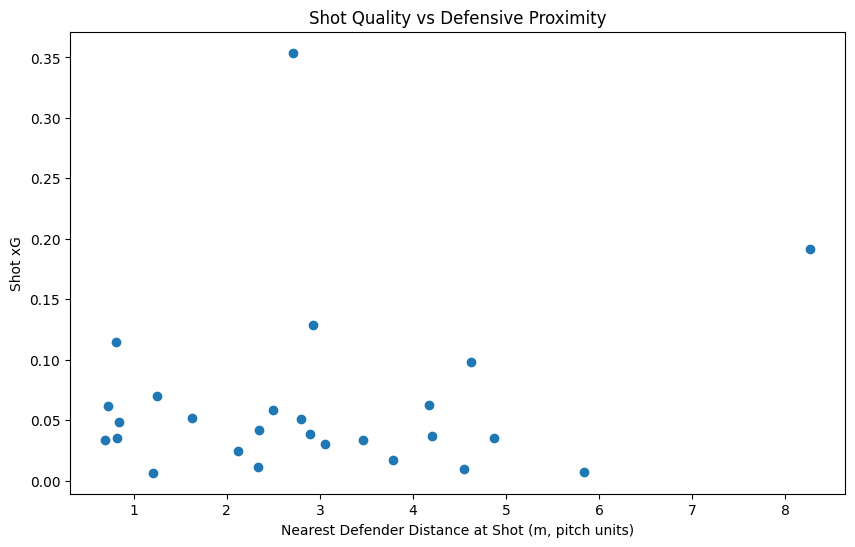

In [17]:
# %%
ff = frames.copy()
ff["loc"] = ff["location"].apply(try_json).apply(parse_point)

# actor row per event
actor = ff[ff["actor"] == 1][["id","loc"]].rename(columns={"loc":"actor_loc"})

# opponent rows per event
# teammate == 1 marks same team as the event's player; we need opponent = 0
opp = ff[ff["teammate"] == 0][["id","loc"]].dropna()

# build per-event nearest distance
def nearest_dist(event_id: str) -> Optional[float]:
    a = actor.loc[actor["id"]==event_id, "actor_loc"]
    if a.empty or a.iloc[0] is None:
        return None
    ax, ay = a.iloc[0]
    opp_pts = opp.loc[opp["id"]==event_id, "loc"].dropna().tolist()
    if not opp_pts:
        return None
    return float(min(math.hypot(ax - x, ay - y) for x,y in opp_pts))

shots_ff = shots.merge(actor, left_on="id", right_on="id", how="left")
shots_ff["nearest_defender_dist"] = shots_ff["id"].apply(nearest_dist)

print(shots_ff[["team","player","minute","second","xg","nearest_defender_dist"]].head(12))

# scatter: nearest defender distance vs xG
fig, ax = plt.subplots()
ax.scatter(shots_ff["nearest_defender_dist"], shots_ff["xg"])
ax.set_xlabel("Nearest Defender Distance at Shot (m, pitch units)")
ax.set_ylabel("Shot xG")
ax.set_title("Shot Quality vs Defensive Proximity")
plt.show()


# 11) Freeze-Frame Visual: One Event
Visualize a single event's 360 frame:
- Actor (event player), teammates, opponents, and the visible-area polygon.

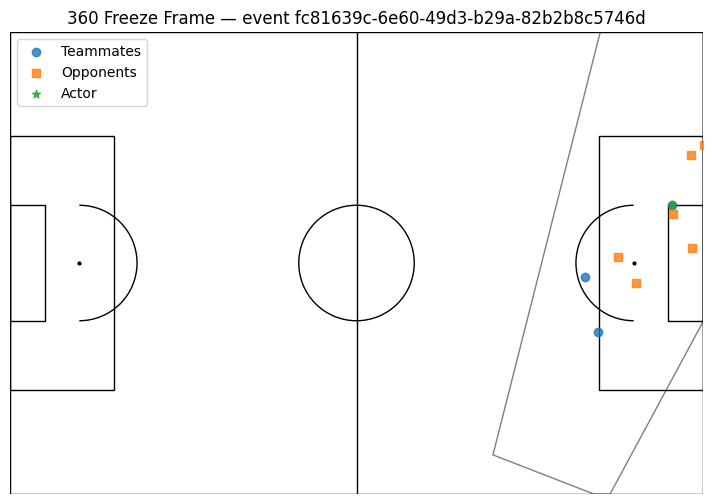

In [18]:
# %%
example_event_id = shots_ff["id"].dropna().astype(str).iloc[0]  # pick a shot
frame_e = ff[ff["id"] == example_event_id].copy()

vis_poly = None
try:
    # visible_area is a list like [x1,y1, x2,y2, ...]
    poly_raw = frames.loc[frames["id"] == example_event_id, "visible_area"].dropna().iloc[0]
    poly = try_json(poly_raw)
    if isinstance(poly, list) and len(poly) >= 6:
        vis_poly = [(poly[i], poly[i+1]) for i in range(0, len(poly), 2)]
except Exception:
    pass

fig, ax = plt.subplots()
draw_pitch(ax)
if vis_poly:
    ax.add_patch(Polygon(vis_poly, closed=True, fill=False, lw=1, alpha=0.5))

# plot players
tm = frame_e[frame_e["teammate"]==1]
op = frame_e[frame_e["teammate"]==0]
act = frame_e[frame_e["actor"]==1]
for df, marker, lbl in [(tm,'o','Teammates'), (op,'s','Opponents'), (act,'*','Actor')]:
    pts = df["loc"].dropna().tolist()
    if pts:
        xs, ys = zip(*pts)
        ax.scatter(xs, ys, marker=marker, label=lbl, alpha=0.8)
ax.legend()
ax.set_title(f"360 Freeze Frame — event {example_event_id}")
plt.show()


# FCpython style

## Pitch helper (FC Python-style, adapted to 120×80 StatsBomb)
FC Python shows how to draw a pitch using lines/circles/arcs in Matplotlib.
Below is an adapted version for a 120x80 pitch (StatsBomb), with an option to return fig/ax.


In [22]:
# %%
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle, Rectangle
from typing import Tuple, Optional

def fcp_pitch_120x80(return_axes: bool = True, linecolor: str = "black", lw: float = 1.0) -> Tuple[plt.Figure, plt.Axes]:
    """
    Draw a football pitch (StatsBomb 120x80) using FC Python's Matplotlib approach.
    Returns (fig, ax) so you can plot events on top.
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    # Outline
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    # Halfway line
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)

    # Penalty areas
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))      # left PA
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))     # right PA

    # Six-yard boxes
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))

    # Spots
    ax.add_patch(Circle((12, 40), 0.8, color=linecolor))   # left pen spot
    ax.add_patch(Circle((60, 40), 0.8, color=linecolor))   # center spot
    ax.add_patch(Circle((108, 40), 0.8, color=linecolor))  # right pen spot

    # Center circle
    ax.add_patch(Circle((60, 40), 9.15, fill=False, ec=linecolor, lw=lw))

    # Pen arcs
    ax.add_patch(Arc((12, 40), 18.3, 18.3, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 18.3, 18.3, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))

    # Tidy
    ax.set_xlim(0, 120); ax.set_ylim(0, 80)
    ax.set_aspect('equal'); ax.axis('off')
    if return_axes:
        return fig, ax
    return fig, ax  # keep signature consistent


## Shot map — both teams on one pitch (Home left, Away right)
What this does:
- Draws FC Python-style 120x80 pitch.
- Plots *all* shots for both teams together.
- Normalizes directions so Home attacks the left goal and Away attacks the right goal:
  • Home shots are mirrored into the left half when needed.
  • Away shots are mirrored into the right half when needed.
- Marker size ~ xG, goal shots highlighted with edge/marker.


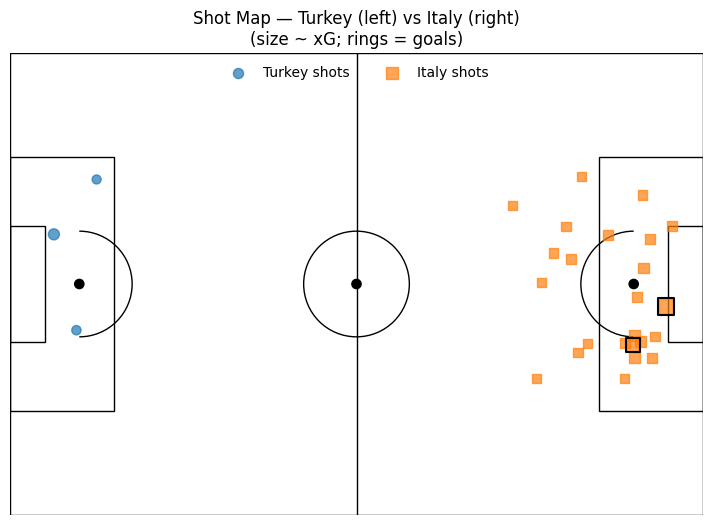

In [24]:
# %%
import json
import numpy as np
import matplotlib.pyplot as plt

# --- 1) Prepare shots (robust JSON -> (x,y)) ---
def _to_xy(val):
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        return float(val[0]), float(val[1])
    try:
        pt = json.loads(val) if isinstance(val, str) else val
        return (float(pt[0]), float(pt[1])) if isinstance(pt, (list, tuple)) and len(pt) >= 2 else (np.nan, np.nan)
    except Exception:
        return (np.nan, np.nan)

shots = events.loc[events["type"] == "Shot"].copy()
shots[["sx", "sy"]] = shots["location"].apply(_to_xy).to_list()
shots["xg"] = pd.to_numeric(shots.get("shot_statsbomb_xg"), errors="coerce")
shots["is_goal"] = (shots.get("shot_outcome") == "Goal")

# --- 2) Identify home/away from matches_df (fallback if missing) ---
home = mrow.iloc[0]["home_team"] if not mrow.empty else shots["team"].dropna().unique()[0]
away = mrow.iloc[0]["away_team"] if not mrow.empty else shots["team"].dropna().unique()[-1]

shots_h = shots.loc[shots["team"] == home].copy()
shots_a = shots.loc[shots["team"] == away].copy()

# --- 3) Vectorized mirroring so: Home attacks LEFT, Away attacks RIGHT ---
# Mirror function in array form: (x, y) -> (120-x, 80-y)
def mirror_array(arr):
    out = arr.copy()
    out[:, 0] = 120.0 - out[:, 0]
    out[:, 1] =  80.0 - out[:, 1]
    return out

# Home: any shots with x > 60 should be mirrored to left half
mask_h = (shots_h["sx"] > 60) & shots_h["sx"].notna() & shots_h["sy"].notna()
if mask_h.any():
    arr = shots_h.loc[mask_h, ["sx", "sy"]].to_numpy(dtype=float, copy=True)
    shots_h.loc[mask_h, ["sx", "sy"]] = mirror_array(arr)

# Away: any shots with x < 60 should be mirrored to right half
mask_a = (shots_a["sx"] < 60) & shots_a["sx"].notna() & shots_a["sy"].notna()
if mask_a.any():
    arr = shots_a.loc[mask_a, ["sx", "sy"]].to_numpy(dtype=float, copy=True)
    shots_a.loc[mask_a, ["sx", "sy"]] = mirror_array(arr)

# --- 4) Plot on FC Python pitch ---
fig, ax = fcp_pitch_120x80()

# Home (circles)
ax.scatter(
    shots_h["sx"], shots_h["sy"],
    s=40 + 200 * shots_h["xg"].fillna(0.0),
    alpha=0.7, label=f"{home} shots", zorder=3
)
hg = shots_h.loc[shots_h["is_goal"] == True]
if not hg.empty:
    ax.scatter(
        hg["sx"], hg["sy"],
        s=60 + 220 * hg["xg"].fillna(0.0),
        facecolors="none", edgecolors="black", linewidths=1.5,
        zorder=4
    )

# Away (squares)
ax.scatter(
    shots_a["sx"], shots_a["sy"],
    s=40 + 200 * shots_a["xg"].fillna(0.0),
    alpha=0.7, label=f"{away} shots", marker="s", zorder=3
)
ag = shots_a.loc[shots_a["is_goal"] == True]
if not ag.empty:
    ax.scatter(
        ag["sx"], ag["sy"],
        s=60 + 220 * ag["xg"].fillna(0.0),
        facecolors="none", edgecolors="black", linewidths=1.5,
        marker="s", zorder=4
    )

ax.legend(loc="upper center", ncol=2, frameon=False)
ax.set_title(f"Shot Map — {home} (left) vs {away} (right)\n(size ~ xG; rings = goals)")
plt.show()


## Progressive Passes — Arrows on FC Python Pitch
What you get:
- Identify progressive passes with a pragmatic rule toward (120, 40).
- Plot arrows for both teams on one pitch.
Notes:
- Arrow width scales with pass length; opacity is light to avoid clutter.


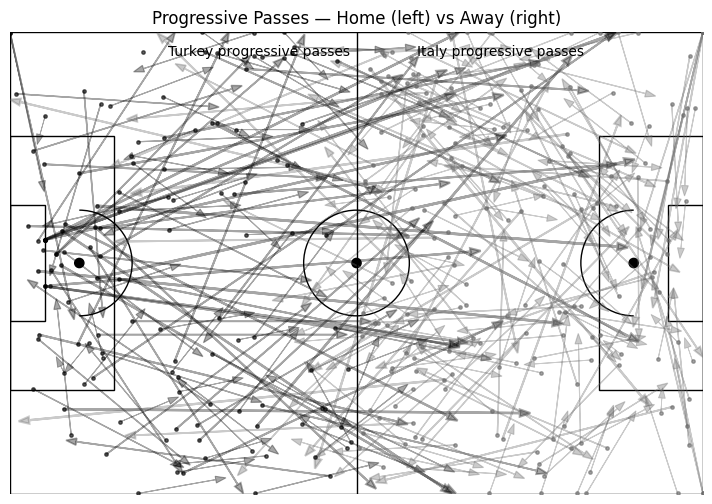

In [26]:
# %%
import json, math, numpy as np, pandas as pd, matplotlib.pyplot as plt

# Helpers if not already defined
if 'try_json' not in globals():
    def try_json(x):
        if pd.isna(x): return None
        if isinstance(x, (list, dict)): return x
        s = str(x)
        try:
            return json.loads(s)
        except Exception:
            try: return json.loads(s.replace("'", '"'))
            except Exception: return None

def parse_xy(val):
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        return float(val[0]), float(val[1])
    j = try_json(val)
    if isinstance(j, (list, tuple)) and len(j) >= 2:
        return float(j[0]), float(j[1])
    return (np.nan, np.nan)

def is_progressive(s, e, thresh_m=10.0):
    if s is None or e is None: return False
    sx, sy = s; ex, ey = e
    if np.isnan([sx, sy, ex, ey]).any(): return False
    start_to_goal = math.hypot(120 - sx, 40 - sy)
    end_to_goal   = math.hypot(120 - ex,  40 - ey)
    closer = (start_to_goal - end_to_goal) >= thresh_m
    in_box = (102 <= ex <= 120) and (18 <= ey <= 62)
    return bool(closer or in_box)

# Build pass table
passes = events.loc[events["type"] == "Pass"].copy()
passes["start"] = passes["location"].apply(parse_xy)
passes["end"]   = passes["pass_end_location"].apply(parse_xy)

passes["is_progressive"] = passes.apply(lambda r: is_progressive(r["start"], r["end"]), axis=1)

# Home/away inference
home = mrow.iloc[0]["home_team"] if 'mrow' in globals() and not mrow.empty else passes["team"].dropna().unique()[0]
away = mrow.iloc[0]["away_team"] if 'mrow' in globals() and not mrow.empty else passes["team"].dropna().unique()[-1]

ph = passes[(passes["team"] == home) & (passes["is_progressive"])].copy()
pa = passes[(passes["team"] == away) & (passes["is_progressive"])].copy()

# Normalize directions to match shot map convention:
#   Home progresses LEFT, Away progresses RIGHT
def mirror_if_needed(df, side):
    if df.empty: return df
    x0 = df["start"].apply(lambda p: p[0] if isinstance(p, tuple) else np.nan)
    need_home = (side == "home") & (x0 > 60)
    need_away = (side == "away") & (x0 < 60)
    need = (need_home | need_away).fillna(False)
    if need.any():
        def mir(pt): 
            x, y = pt
            return (120.0 - x, 80.0 - y)
        df.loc[need, "start"] = df.loc[need, "start"].apply(mir)
        df.loc[need, "end"]   = df.loc[need, "end"].apply(mir)
    return df

ph = mirror_if_needed(ph, "home")
pa = mirror_if_needed(pa, "away")

# Plot arrows
fig, ax = fcp_pitch_120x80()

def plot_arrows(df, color, label, marker_every=1):
    if df.empty: 
        return
    xs = df["start"].apply(lambda p: p[0]).to_numpy()
    ys = df["start"].apply(lambda p: p[1]).to_numpy()
    xe = df["end"].apply(lambda p: p[0]).to_numpy()
    ye = df["end"].apply(lambda p: p[1]).to_numpy()
    dx = xe - xs
    dy = ye - ys
    # scale linewidth by pass length
    lw = 0.5 + 0.015 * np.hypot(dx, dy)
    # plot
    for i in range(0, len(xs), marker_every):
        ax.arrow(xs[i], ys[i], dx[i], dy[i], head_width=1.2, head_length=1.8,
                 length_includes_head=True, fc=color, ec=color, alpha=0.35, linewidth=lw[i])
    ax.scatter(xs, ys, s=6, label=label, color=color, alpha=0.6, zorder=3)

plot_arrows(ph, color="black", label=f"{home} progressive passes")
plot_arrows(pa, color="dimgray", label=f"{away} progressive passes")

ax.legend(loc="upper center", ncol=2, frameon=False)
ax.set_title("Progressive Passes — Home (left) vs Away (right)")
plt.show()


yuck

## Passing Network — FC Python Pitch (self-contained)
What you get:
- Nodes sized by touches; edges weighted by pass counts between teammates.
- Computed inside this cell to avoid dependencies on earlier variables.
Tip: If you have player names, we'll try to annotate a few key nodes.


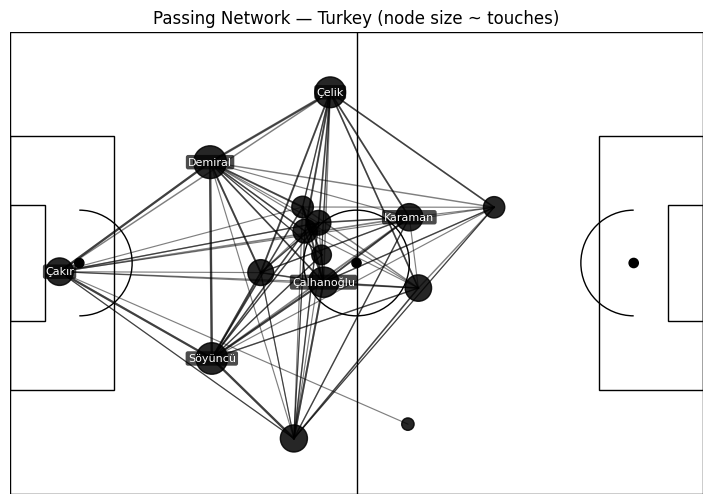

In [27]:
# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt

team_focus = mrow.iloc[0]["home_team"] if 'mrow' in globals() and not mrow.empty else events["team"].dropna().unique()[0]

# Base tables
passes_team = events[(events["type"]=="Pass") & (events["team"]==team_focus)].copy()
passes_team["start"] = passes_team["location"].apply(parse_xy)
passes_team["end"]   = passes_team["pass_end_location"].apply(parse_xy)
# completed passes (StatsBomb: pass_outcome is NaN when completed)
passes_team_ok = passes_team[passes_team["pass_outcome"].isna()].copy()

# Edge weights
pair_counts = passes_team_ok.groupby(["player_id","pass_recipient_id"], dropna=True).size().rename("count").reset_index()

# Touches per player (using all team events)
touch_counts = events[(events["team"]==team_focus) & events["player_id"].notna()].groupby("player_id").size().rename("touches").reset_index()

# Anchor positions: average of pass starts and receipt ends
def mean_pos(series):
    pts = [p for p in series if isinstance(p, tuple)]
    return np.nanmean(np.array(pts), axis=0) if pts else np.array([60.0, 40.0])

start_pos = passes_team_ok.groupby("player_id")["start"].apply(mean_pos)
recv_pos  = passes_team_ok.groupby("pass_recipient_id")["end"].apply(mean_pos)
avg_pos = pd.DataFrame({
    "player_id": start_pos.index,
    "x": [p[0] for p in start_pos.values],
    "y": [p[1] for p in start_pos.values]
}).merge(
    pd.DataFrame({
        "player_id": recv_pos.index,
        "x2": [p[0] for p in recv_pos.values],
        "y2": [p[1] for p in recv_pos.values]
    }),
    how="outer", on="player_id"
)
avg_pos["x"] = avg_pos[["x","x2"]].mean(axis=1)
avg_pos["y"] = avg_pos[["y","y2"]].mean(axis=1)
avg_pos = avg_pos.drop(columns=["x2","y2"]).merge(touch_counts, on="player_id", how="left")

# Plot
fig, ax = fcp_pitch_120x80()

# edges
for r in pair_counts.itertuples(index=False):
    a = avg_pos.loc[avg_pos["player_id"]==r.player_id, ["x","y"]].values
    b = avg_pos.loc[avg_pos["player_id"]==r.pass_recipient_id, ["x","y"]].values
    if len(a)==1 and len(b)==1 and not np.isnan(a).any() and not np.isnan(b).any():
        ax.plot([a[0,0], b[0,0]], [a[0,1], b[0,1]],
                linewidth=0.5 + 0.5*np.log1p(r.count), alpha=0.5, color="black")

# nodes
sizes = 50 + 3*avg_pos["touches"].fillna(0.0)
ax.scatter(avg_pos["x"], avg_pos["y"], s=sizes, zorder=3, color="black", alpha=0.85)

# Optional: annotate a few most-involved players
if "player" in events.columns:
    top_ids = avg_pos.sort_values("touches", ascending=False)["player_id"].head(6).dropna().astype(float).astype(int).tolist()
    name_map = events.dropna(subset=["player_id","player"]).drop_duplicates(subset=["player_id"])[["player_id","player"]]
    name_map["player_id"] = name_map["player_id"].astype(float).astype(int)
    lab = avg_pos.merge(name_map, on="player_id", how="left")
    for r in lab.itertuples(index=False):
        if r.player_id in top_ids and not (np.isnan(r.x) or np.isnan(r.y)):
            ax.text(r.x, r.y, (r.player or str(r.player_id)).split()[-1], ha="center", va="center",
                    fontsize=8, color="white", bbox=dict(boxstyle="round,pad=0.2", fc="black", ec="none", alpha=0.7))

ax.set_title(f"Passing Network — {team_focus} (node size ~ touches)")
plt.show()


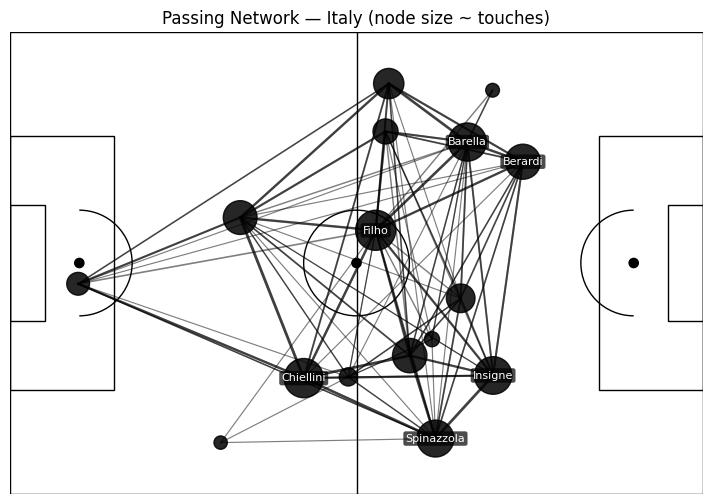

In [28]:
# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt

team_focus = mrow.iloc[0]["away_team"] if 'mrow' in globals() and not mrow.empty else events["team"].dropna().unique()[0]

# Base tables
passes_team = events[(events["type"]=="Pass") & (events["team"]==team_focus)].copy()
passes_team["start"] = passes_team["location"].apply(parse_xy)
passes_team["end"]   = passes_team["pass_end_location"].apply(parse_xy)
# completed passes (StatsBomb: pass_outcome is NaN when completed)
passes_team_ok = passes_team[passes_team["pass_outcome"].isna()].copy()

# Edge weights
pair_counts = passes_team_ok.groupby(["player_id","pass_recipient_id"], dropna=True).size().rename("count").reset_index()

# Touches per player (using all team events)
touch_counts = events[(events["team"]==team_focus) & events["player_id"].notna()].groupby("player_id").size().rename("touches").reset_index()

# Anchor positions: average of pass starts and receipt ends
def mean_pos(series):
    pts = [p for p in series if isinstance(p, tuple)]
    return np.nanmean(np.array(pts), axis=0) if pts else np.array([60.0, 40.0])

start_pos = passes_team_ok.groupby("player_id")["start"].apply(mean_pos)
recv_pos  = passes_team_ok.groupby("pass_recipient_id")["end"].apply(mean_pos)
avg_pos = pd.DataFrame({
    "player_id": start_pos.index,
    "x": [p[0] for p in start_pos.values],
    "y": [p[1] for p in start_pos.values]
}).merge(
    pd.DataFrame({
        "player_id": recv_pos.index,
        "x2": [p[0] for p in recv_pos.values],
        "y2": [p[1] for p in recv_pos.values]
    }),
    how="outer", on="player_id"
)
avg_pos["x"] = avg_pos[["x","x2"]].mean(axis=1)
avg_pos["y"] = avg_pos[["y","y2"]].mean(axis=1)
avg_pos = avg_pos.drop(columns=["x2","y2"]).merge(touch_counts, on="player_id", how="left")

# Plot
fig, ax = fcp_pitch_120x80()

# edges
for r in pair_counts.itertuples(index=False):
    a = avg_pos.loc[avg_pos["player_id"]==r.player_id, ["x","y"]].values
    b = avg_pos.loc[avg_pos["player_id"]==r.pass_recipient_id, ["x","y"]].values
    if len(a)==1 and len(b)==1 and not np.isnan(a).any() and not np.isnan(b).any():
        ax.plot([a[0,0], b[0,0]], [a[0,1], b[0,1]],
                linewidth=0.5 + 0.5*np.log1p(r.count), alpha=0.5, color="black")

# nodes
sizes = 50 + 3*avg_pos["touches"].fillna(0.0)
ax.scatter(avg_pos["x"], avg_pos["y"], s=sizes, zorder=3, color="black", alpha=0.85)

# Optional: annotate a few most-involved players
if "player" in events.columns:
    top_ids = avg_pos.sort_values("touches", ascending=False)["player_id"].head(6).dropna().astype(float).astype(int).tolist()
    name_map = events.dropna(subset=["player_id","player"]).drop_duplicates(subset=["player_id"])[["player_id","player"]]
    name_map["player_id"] = name_map["player_id"].astype(float).astype(int)
    lab = avg_pos.merge(name_map, on="player_id", how="left")
    for r in lab.itertuples(index=False):
        if r.player_id in top_ids and not (np.isnan(r.x) or np.isnan(r.y)):
            ax.text(r.x, r.y, (r.player or str(r.player_id)).split()[-1], ha="center", va="center",
                    fontsize=8, color="white", bbox=dict(boxstyle="round,pad=0.2", fc="black", ec="none", alpha=0.7))

ax.set_title(f"Passing Network — {team_focus} (node size ~ touches)")
plt.show()


## Shot Quality vs Nearest Defender (360) — Scatter
What you get:
- For shots with a 360 frame, compute distance to the nearest opponent at the shot.
- Scatter: distance vs shot xG (expect a positive relationship).


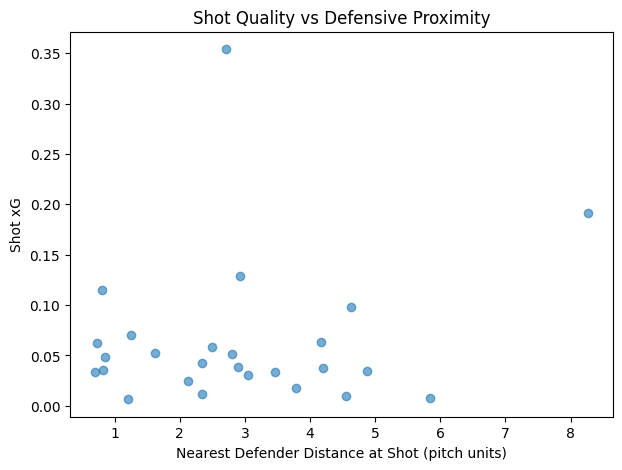

In [29]:
# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt, math, json

# Rebuild minimal shots with xG
shots = events.loc[events["type"]=="Shot"].copy()
shots["xg"] = pd.to_numeric(shots.get("shot_statsbomb_xg"), errors="coerce")

# Frames prep
ff = frames.copy()
def to_xy_safe(v):
    try:
        j = json.loads(v) if isinstance(v, str) else v
        return (float(j[0]), float(j[1])) if isinstance(j, (list, tuple)) and len(j)>=2 else None
    except Exception:
        return None

ff["loc"] = ff["location"].apply(to_xy_safe)

actor = ff[ff["actor"]==1][["id","loc"]].rename(columns={"loc":"actor_loc"})
oppo  = ff[ff["teammate"]==0][["id","loc"]].dropna()

def nearest_dist(eid):
    a = actor.loc[actor["id"]==eid, "actor_loc"]
    if a.empty or a.iloc[0] is None: return np.nan
    ax, ay = a.iloc[0]
    O = oppo.loc[oppo["id"]==eid, "loc"].dropna().tolist()
    if not O: return np.nan
    return float(min(math.hypot(ax-x, ay-y) for x,y in O))

shots_ff = shots.merge(actor, on="id", how="left")
shots_ff["nearest_defender_dist"] = shots_ff["id"].apply(nearest_dist)

# Scatter
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(shots_ff["nearest_defender_dist"], shots_ff["xg"], alpha=0.6)
ax.set_xlabel("Nearest Defender Distance at Shot (pitch units)")
ax.set_ylabel("Shot xG")
ax.set_title("Shot Quality vs Defensive Proximity")
plt.show()


## 360 Freeze-Frame — One Event on FC Python Pitch
What you get:
- Actor (*), Teammates (o), Opponents (s), and the visible-area polygon.
Tip:
- Change `example_event_id` to explore different plays (e.g., a big chance).


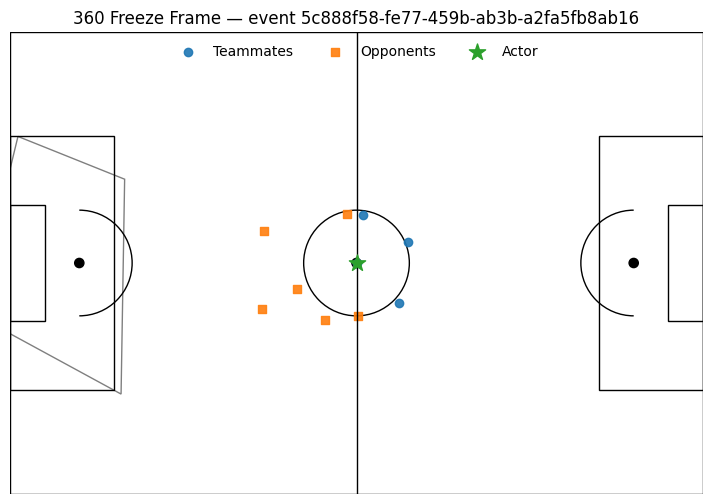

In [33]:
# %%
import json
from matplotlib.patches import Polygon

# Choose a shot event that has frames
cand = frames["id"].dropna().astype(str)
example_event_id = cand.iloc[0] if not cand.empty else None

fig, ax = fcp_pitch_120x80()

if example_event_id is None:
    ax.set_title("No 360 events available in this file.")
    plt.show()
else:
    frame_e = frames.loc[frames["id"] == example_event_id].copy()
    # visible area polygon
    vis_poly = None
    va = frame_e["visible_area"].dropna()
    if not va.empty:
        poly = json.loads(va.iloc[0]) if isinstance(va.iloc[0], str) else va.iloc[0]
        if isinstance(poly, list) and len(poly) >= 6:
            vis_poly = [(poly[i], poly[i+1]) for i in range(0, len(poly), 2)]
            ax.add_patch(Polygon(vis_poly, closed=True, fill=False, lw=1, alpha=0.5))

    # split roles
    def to_xy_list(series):
        pts = []
        for v in series.dropna():
            p = json.loads(v) if isinstance(v, str) else v
            if isinstance(p, (list, tuple)) and len(p)>=2:
                pts.append((float(p[0]), float(p[1])))
        return list(zip(*pts)) if pts else ([], [])

    tm_x, tm_y = to_xy_list(frame_e.loc[frame_e["teammate"]==1, "location"])
    op_x, op_y = to_xy_list(frame_e.loc[frame_e["teammate"]==0, "location"])
    ac_x, ac_y = to_xy_list(frame_e.loc[frame_e["actor"]==1, "location"])

    ax.scatter(tm_x, tm_y, label="Teammates", alpha=0.9)
    ax.scatter(op_x, op_y, marker="s", label="Opponents", alpha=0.9)
    ax.scatter(ac_x, ac_y, marker="*", s=150, label="Actor", zorder=4)

    ax.legend(loc="upper center", ncol=3, frameon=False)
    ax.set_title(f"360 Freeze Frame — event {example_event_id}")
    plt.show()


## Field Tilt — Final-Third Share (bar)
What you get:
- Share of final-third touches (passes/carries/receipts/dribbles/shots) for each team.
- Simple, easy-to-read bar chart.


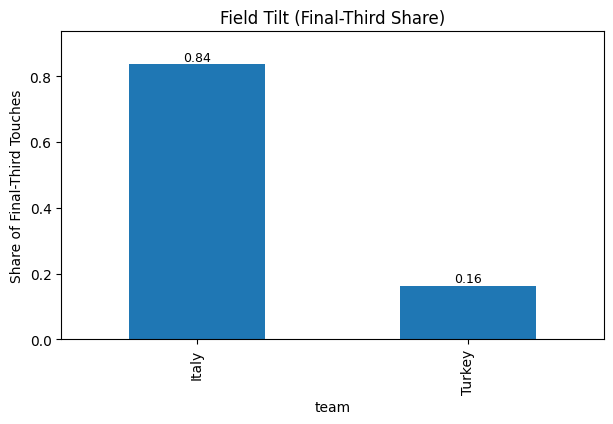

In [34]:
# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def parse_xy_quick(v):
    try:
        j = json.loads(v) if isinstance(v, str) else v
        return (float(j[0]), float(j[1])) if isinstance(j, (list, tuple)) and len(j)>=2 else None
    except Exception:
        return None

touchlike = events[events["type"].isin(["Pass","Carry","Ball Receipt*","Dribble","Shot"])].copy()
touchlike["pt"] = touchlike["location"].apply(parse_xy_quick)

def in_final_third(pt):
    return bool(pt and pt[0] >= 80.0)

ft = touchlike.loc[touchlike["pt"].apply(in_final_third)]
tilt = (ft.groupby("team")["id"].count() / ft["id"].count()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7,4))
tilt.plot(kind="bar", ax=ax)
ax.set_ylabel("Share of Final-Third Touches")
ax.set_title("Field Tilt (Final-Third Share)")
for i, v in enumerate(tilt.values):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
plt.ylim(0, min(1.0, tilt.max() + 0.1))
plt.show()


## PPDA — Pressing Proxy (bar)
What you get:
- PPDA ≈ Opponent passes per your defensive actions in advanced zones (x ≥ 48).
- Lower PPDA → more intense pressing.


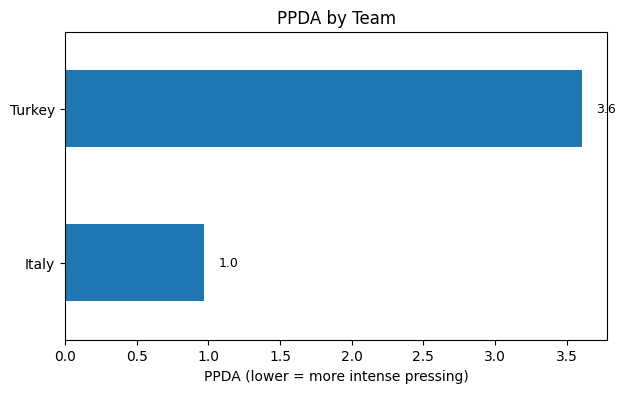

In [35]:
# %%
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def in_pressing_zone(pt):
    return bool(pt and pt[0] >= 48.0)

events["_pt"] = events["location"].apply(parse_xy_quick)

passes_mask = (events["type"] == "Pass")
def_actions_mask = events["type"].isin(["Pressure","Foul Committed","Duel","Interception","Tackle","Block"])

teams = events["team"].dropna().unique()
ppda_vals = {}

for team in teams:
    opp_mask = (events["team"] != team)
    opp_passes = events[passes_mask & events["_pt"].apply(in_pressing_zone) & opp_mask]["id"].count()
    def_actions = events[def_actions_mask & events["_pt"].apply(in_pressing_zone) & (events["team"] == team)]["id"].count()
    ppda_vals[team] = (opp_passes / def_actions) if def_actions > 0 else np.nan

ppda = pd.Series(ppda_vals).sort_values()

fig, ax = plt.subplots(figsize=(7,4))
ppda.plot(kind="barh", ax=ax)
ax.set_xlabel("PPDA (lower = more intense pressing)")
ax.set_title("PPDA by Team")
for i, v in enumerate(ppda.values):
    if not np.isnan(v):
        ax.text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=9)
plt.show()
